# Nowcasting Meteosat imagery over Ireland with a fine-tuned transformer

This project forecasts what the new **Meteosat Third Generation** satellite will see over Ireland one
and two hours from now.

It starts from NVIDIA's [StormScope-Meteosat](https://huggingface.co/nvidia/stormscope-meteosat), a
diffusion **transformer** pre-trained to predict the next satellite image 10 minutes ahead over
Europe. We keep its 613 million weights frozen and train small **LoRA** adapters (about 0.1% of the
weights) so that it works on **hourly time series** of images over Ireland. The forecasts are then
compared with two baselines: **persistence** (the next hour looks like the last one) and the
**untouched pre-trained model**.

All the code lives in the `earth_forecasting` package
([GitHub](https://github.com/mich3leRusso/earth-forecasting)); this notebook only calls it and shows
the results. The trained adapter is on the Hugging Face Hub at
[`michele007rok/StormScope_Ireland`](https://huggingface.co/michele007rok/StormScope_Ireland).

In [1]:
import numpy as np
import torch
from physicsnemo.experimental.peft import is_lora_layer

from earth_forecasting import plots
from earth_forecasting.config import load_config
from earth_forecasting.data import FrameWindows
from earth_forecasting.evaluate import finetuned_model

train_cfg = load_config("train.yaml", args=[])  # how the adapter was trained
cfg = load_config("evaluate.yaml", args=[])     # how it is tested: unseen dates, adapter from the Hub
step = np.timedelta64(cfg.data.step_minutes, "m")

/tmp/ipykernel_271405/3756547587.py:3: ExperimentalFeatureWarning: You are importing from 'physicsnemo.experimental'. The APIs in this namespace are experimental, under active development, and may change without notice. Expect possible back-compatibility breaking changes and only partial test coverage.
  from physicsnemo.experimental.peft import is_lora_layer


/home/michele/earth-forecasting/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data: hourly satellite images

The data are **Level 1c images from the Flexible Combined Imager (FCI)** on Meteosat-12 (MTG-I1),
downloaded from the [EUMETSAT Data Store](https://data.eumetsat.int). Each image has **16 channels**:
5 visible, 3 near-infrared, 2 water-vapour and 6 thermal-infrared bands. That lets the model see
clouds in daylight and their temperature day and night.

We crop the full disk to Ireland, which gives 128 × 224 pixels at the satellite's 2 km grid (about
3–4 km on the ground at this latitude), and keep one image per hour.

**One sample** is a short time series: six consecutive hourly images (the last five hours and now)
plus the image one hour later, which is the target. The periods are split in time, never mixed:

| | Forecast start times | Purpose |
|---|---|---|
| Training | 1 June – 31 August 2026 | fit the adapters |
| Validation | 2 – 8 September 2026 | choose the best epoch |
| Test | 1 – 7 October 2026 | final scores, seen by nothing else |

NVIDIA trained the base model on November 2024 – May 2026, so every date here is new to it.
A handful of hours are missing or incomplete on EUMETSAT's side, and the windows that touch them are
skipped.

training     2185 windows
validation    168 windows
test          168 windows


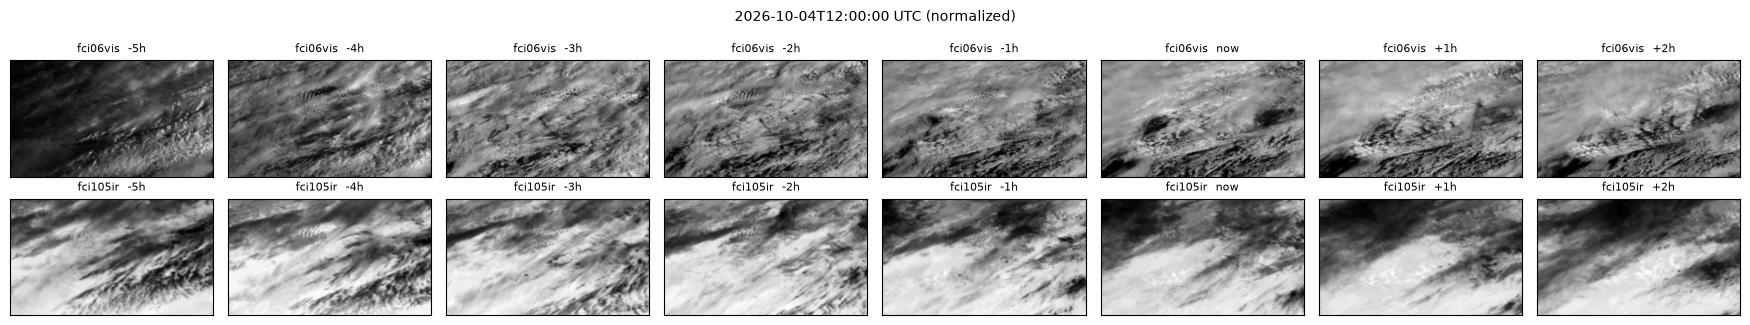

In [2]:
for name, c, split in [("training", train_cfg, "train"), ("validation", train_cfg, "val"), ("test", cfg, "test")]:
    print(f"{name:<11} {len(FrameWindows(*c.data[split], c.data.dir, step)):5d} windows")

test = FrameWindows(*cfg.data.test, cfg.data.dir, step, lead_steps=cfg.eval.lead_steps)
model, adapter = finetuned_model(cfg)
example = test[len(test) // 2]  # six context frames + the two observed hours after them
plots.window_figure(model, *example);

## 2. Model: a pre-trained diffusion transformer, fine-tuned with LoRA

Each of StormScope's two "experts" is a **Diffusion Transformer (DiT)**: the image is cut into
4 × 4-pixel patches, which become tokens, and 16 transformer blocks process them with
neighborhood attention and MLPs. A forecast starts from noise and is refined over 48 denoising
steps, each conditioned on the six past images, the sun angles and the terrain. One expert handles
the noisy early steps (large-scale structure), the other the fine detail at the end.

The original model predicts 10 minutes ahead. We switch it to **one-hour steps**: it reads six
hourly images and predicts the next hour. To go further, it feeds its own prediction back in.
The pre-trained weights stay frozen; we train **LoRA adapters** (rank 8) on the attention
projections of the last 8 blocks of both experts, plus the final layer that turns tokens back into
the 16 channels.

In [3]:
lora = sum(p.numel() for m in model.modules() if is_lora_layer(m) for n, p in m.named_parameters(recurse=False) if "lora" in n)
total = sum(p.numel() for p in model.parameters())
print(f"adapter: {adapter}")
print(f"trained: {lora:,} of {total:,} weights ({lora / total:.2%})")

adapter: /home/michele/.cache/huggingface/hub/models--michele007rok--StormScope_Ireland/snapshots/0c4d578517657e01c0903c97b6bf28aa0a0bf125/best.pt
trained: 606,208 of 613,172,736 weights (0.10%)


## 3. Training

Training runs on a laptop GPU with 8 GB of memory, so the batch size is 1, with gradients
accumulated over 8 samples. Each sample trains one expert on the standard diffusion
(denoising) loss. We use the Muon optimizer with a linear warmup and a cosine learning-rate decay,
for 12 epochs over the 2,185 training windows: about 14 minutes per epoch.

Epoch 0 is the untouched pre-trained model on the validation week, which gives the starting point.

,train/loss,val/loss
epoch,,
0,NaN,0.5238
1,0.3681,0.4519
2,0.3167,0.4245
3,0.3063,0.4108
4,0.3110,0.4022
5,0.3043,0.4004
6,0.3052,0.3974
7,0.2924,0.3945
8,0.3060,0.3919


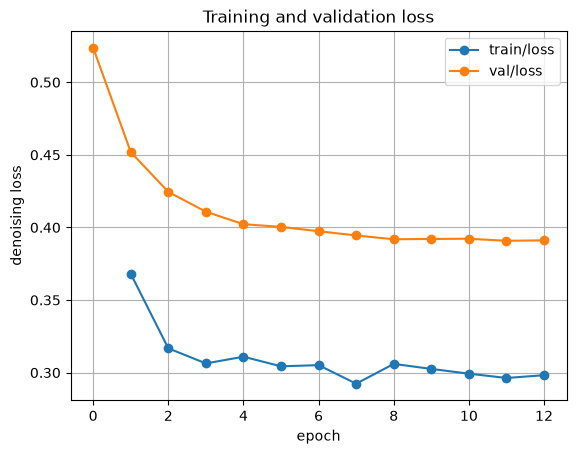

In [4]:
curves = plots.training_curves(train_cfg.output.tensorboard)
ax = curves.plot(marker="o", xlabel="epoch", ylabel="denoising loss", title="Training and validation loss", grid=True)
curves.round(4)

## 4. Evaluation on unseen dates (October 2026)

For 20 forecast start times spread over the test week, each model forecasts one and two hours
ahead, and every forecast is compared with what the satellite actually observed. The score is the
**RMSE** over all land and sea pixels, computed per channel on the normalized scale so that the 16
channels are comparable. Lower is better.

Both models use the same diffusion noise for each date, so the difference between them comes from
the adapters alone. The last two columns show how much each model improves on persistence.

model,fine-tuned,base,persistence,fine-tuned vs persistence,base vs persistence
lead_hours,,,,,
1.0,0.344,0.354,0.425,+19%,+17%
2.0,0.434,0.491,0.582,+25%,+16%


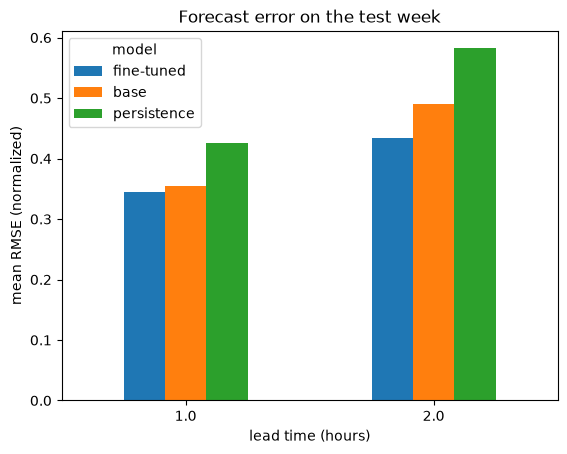

In [5]:
mean, per_channel = plots.rmse_summary(f"{cfg.output.tensorboard}/rmse_test.csv")
mean[plots.MODELS].plot.bar(rot=0, xlabel="lead time (hours)", ylabel="mean RMSE (normalized)", title="Forecast error on the test week")
mean

In [6]:
per_channel.round(3)

lead_hours        1.0                           2.0                   
model      fine-tuned   base persistence fine-tuned   base persistence
channel                                                               
fci04vis        0.259  0.309       0.389      0.354  0.518       0.647
fci05vis        0.318  0.352       0.428      0.414  0.559       0.668
fci06vis        0.361  0.377       0.445      0.454  0.560       0.645
fci08vis        0.349  0.366       0.427      0.436  0.543       0.626
fci09vis        0.358  0.372       0.440      0.449  0.534       0.620
fci13nir        0.513  0.516       0.635      0.593  0.635       0.773
fci16nir        0.332  0.342       0.376      0.401  0.473       0.536
fci22nir        0.329  0.342       0.378      0.404  0.472       0.532
fci38ir         0.258  0.261       0.309      0.340  0.362       0.433
fci63wv         0.171  0.191       0.248      0.258  0.289       0.367
fci73wv         0.301  0.307       0.382      0.385  0.413       0.501
fci87ir         0.422  0.414       0.504      0.526  0.528       0.631
fci97ir         0.285  0.279       0.336      0.359  0.362       0.419
fci105ir        0.422  0.415       0.508      0.530  0.534       0.642
fci123ir        0.426  0.421       0.513      0.536  0.546       0.652
fci133ir        0.406  0.401       0.490      0.508  0.520       0.619

## 5. One forecast, side by side

The same start time as the example above, for a thermal-infrared channel (cloud-top temperature,
day and night) and a visible one (reflected sunlight). Each row is a lead time. From left to right:
persistence, the pre-trained model, the fine-tuned model, and what the satellite actually saw.

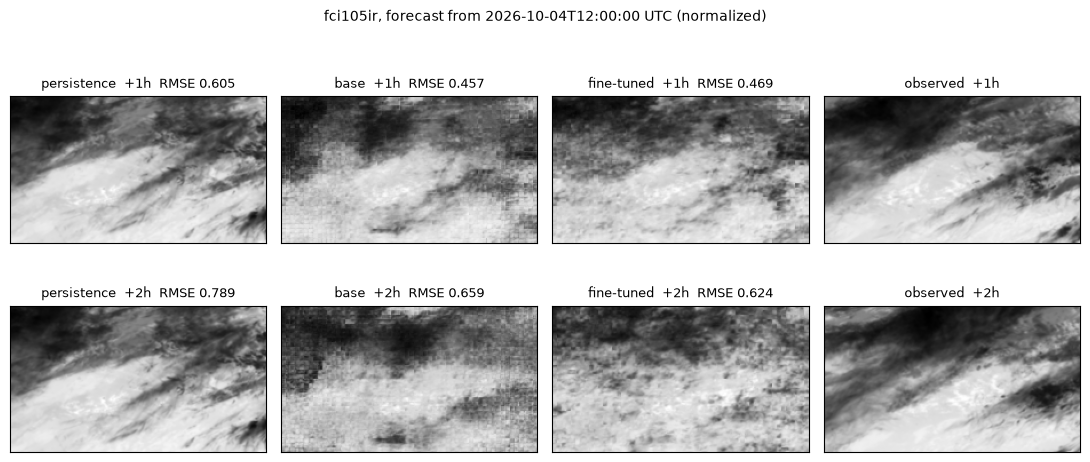

In [7]:
plots.forecast_figure(model, *example, lead_steps=cfg.eval.lead_steps, channel="fci105ir");

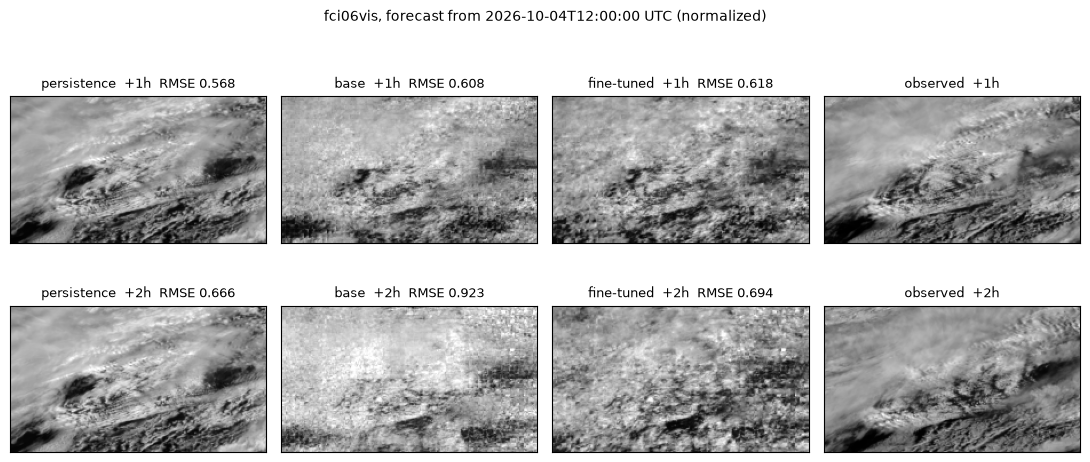

In [8]:
plots.forecast_figure(model, *example, lead_steps=cfg.eval.lead_steps, channel="fci06vis");

## 6. What we learned

- **It works on unseen dates.** On the October test week the fine-tuned model beats persistence by
  **19% at +1h and 25% at +2h**, and the untouched pre-trained model by **3% and 12%**.
- **The gain grows with lead time.** The base model was trained for 10-minute steps; fed hourly
  frames and then its own +1h prediction, it drifts faster. The adapters learned hourly dynamics,
  so at +2h the fine-tuned model is better on all 16 channels.
- **Most of the gain is in reflected sunlight.** Visible and near-infrared channels improve most
  (e.g. `fci04vis` at +2h: 0.354 vs 0.518, about 32% lower). The thermal-infrared channels barely
  move: 1–2% worse than the base model at +1h, 0.4–2% better at +2h.
- **Training only 0.1% of the weights was enough**, on a laptop GPU, in under three hours.

**Limits.** The scores come from 20 start times and a single diffusion sample each, so differences
of 1–2% are within the noise. A diffusion model is probabilistic: an ensemble of samples, scored
with CRPS, would judge it more fairly than the RMSE of one sample. The model only sees the
Ireland crop, so weather arriving from just outside it, mostly from the Atlantic, can't enter the
forecast. And training covered one summer only.

**Next steps:** more test dates and ensemble members, a larger region around Ireland for context,
and a loss weighted per channel to help the thermal-infrared bands.